In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    average_precision_score,
    precision_recall_curve
)

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)

print("Libraries imported successfully!")

C:\Users\madha\AppData\Roaming\Python\Python313\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Libraries imported successfully!


In [2]:
data = pd.read_csv("creditcard.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", data.shape)

data.head()

Dataset loaded successfully!
Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [4]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [5]:
missing_values = data.isnull().sum()

print("Total missing values:", missing_values.sum())

missing_values[missing_values > 0]

Total missing values: 0


Series([], dtype: int64)

In [6]:
duplicate_count = data.duplicated().sum()

print("Duplicate records:", duplicate_count)

print("Duplicate percentage:",
      round((duplicate_count / len(data)) * 100, 3), "%")

Duplicate records: 1081
Duplicate percentage: 0.38 %


## EDA

Normal transactions: 284315
Fraud transactions: 492


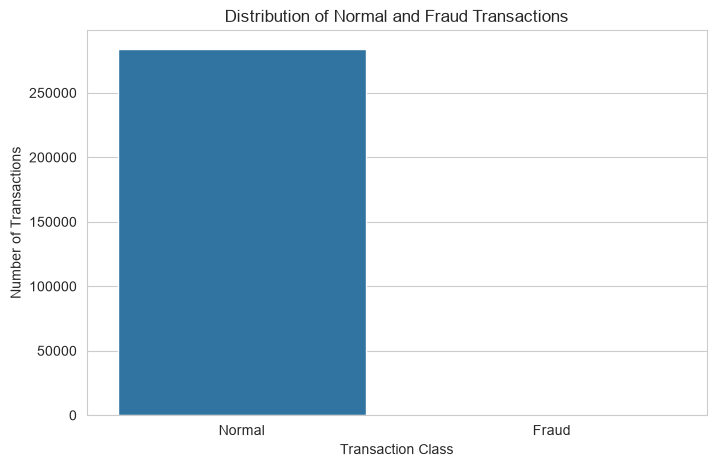

In [7]:
class_counts = data['Class'].value_counts()

print("Normal transactions:", class_counts[0])
print("Fraud transactions:", class_counts[1])

plt.figure(figsize=(8, 5))
sns.countplot(data=data, x='Class')

plt.title("Distribution of Normal and Fraud Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ['Normal', 'Fraud'])
plt.show()

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


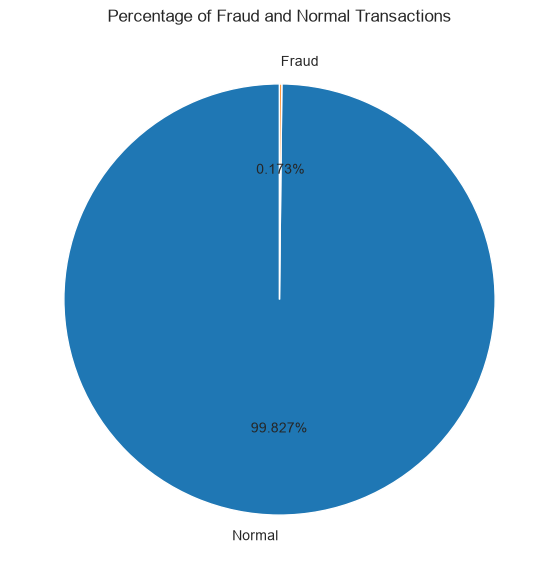

In [8]:
fraud_percentage = data['Class'].value_counts(normalize=True) * 100

print(fraud_percentage)

plt.figure(figsize=(7, 7))
plt.pie(
    fraud_percentage,
    labels=['Normal', 'Fraud'],
    autopct='%1.3f%%',
    startangle=90
)

plt.title("Percentage of Fraud and Normal Transactions")
plt.show()

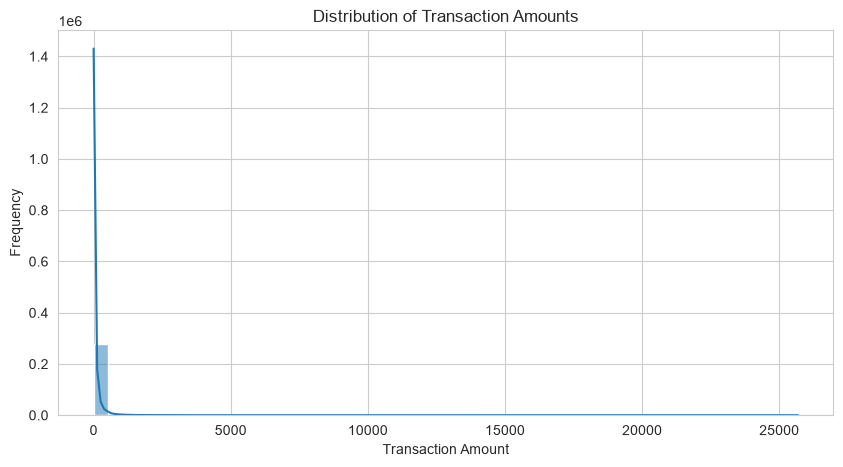

In [9]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data['Amount'],
    bins=50,
    kde=True
)

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.show()

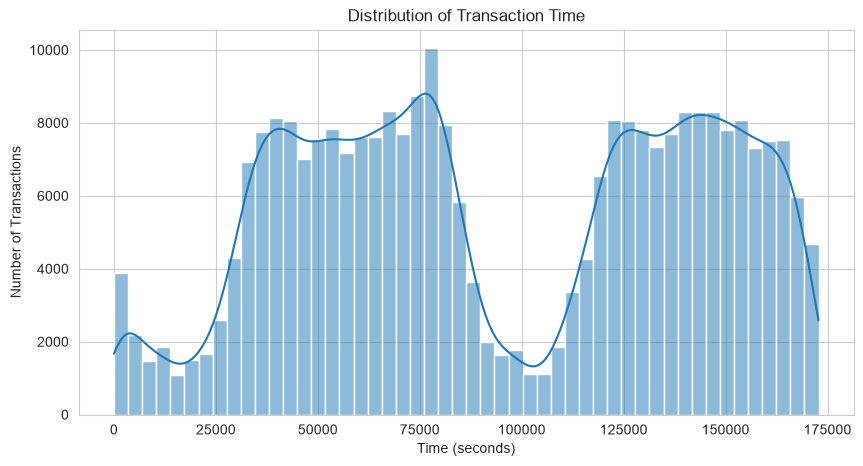

In [10]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data['Time'],
    bins=50,
    kde=True
)

plt.title("Distribution of Transaction Time")
plt.xlabel("Time (seconds)")
plt.ylabel("Number of Transactions")
plt.show()

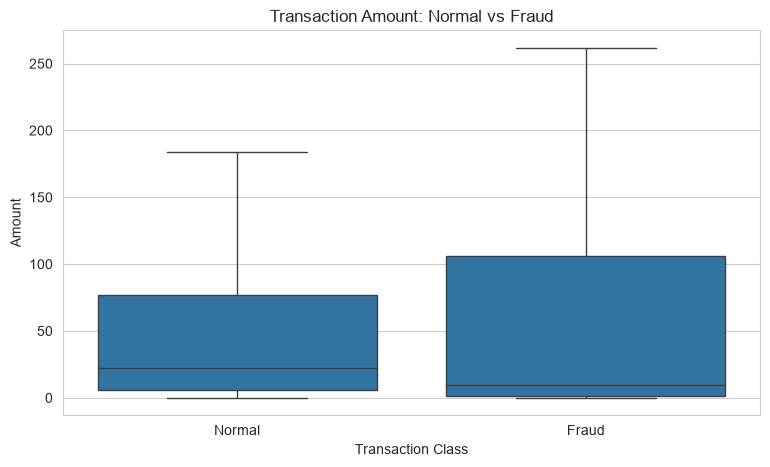

In [11]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=data,
    x='Class',
    y='Amount',
    showfliers=False
)

plt.title("Transaction Amount: Normal vs Fraud")
plt.xlabel("Transaction Class")
plt.ylabel("Amount")
plt.xticks([0, 1], ['Normal', 'Fraud'])

plt.show()

In [12]:
amount_comparison = data.groupby('Class')['Amount'].agg(
    ['mean', 'median', 'min', 'max']
)

amount_comparison.index = ['Normal', 'Fraud']

display(amount_comparison)

,mean,median,min,max
Normal,88.291022,22.00,0.0,25691.16
Fraud,122.211321,9.25,0.0,2125.87


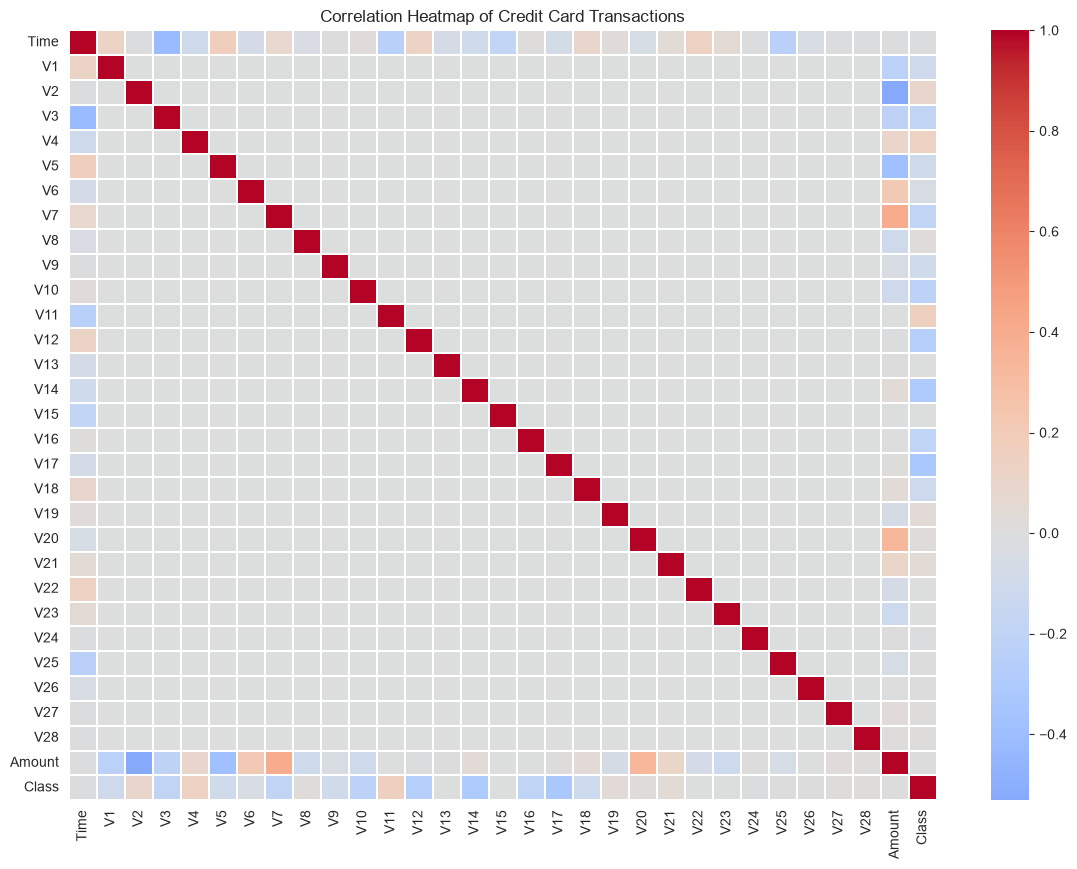

In [13]:
plt.figure(figsize=(14, 10))

correlation = data.corr()

sns.heatmap(
    correlation,
    cmap='coolwarm',
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Credit Card Transactions")
plt.show()

## FEATURE ENGINEER

In [14]:
df = data.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df.shape)

Original dataset shape: (284807, 31)
Working dataset shape: (284807, 31)


In [15]:
df['Amount_log'] = np.log1p(df['Amount'])

print("Amount transformation completed!")

Amount transformation completed!


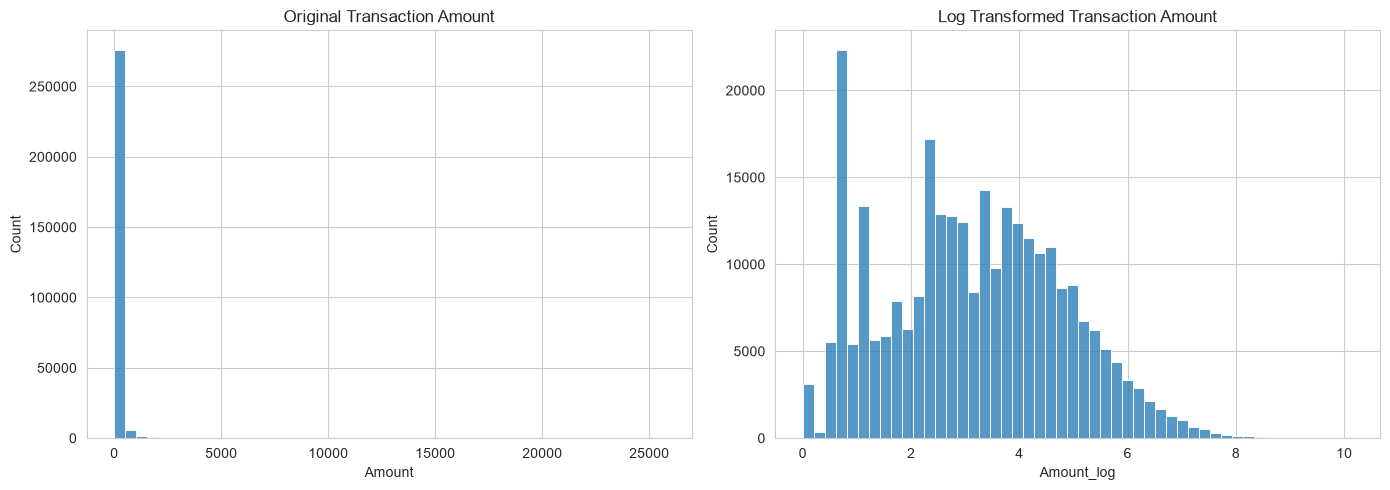

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Amount'], bins=50, ax=axes[0])
axes[0].set_title("Original Transaction Amount")

sns.histplot(df['Amount_log'], bins=50, ax=axes[1])
axes[1].set_title("Log Transformed Transaction Amount")

plt.tight_layout()
plt.show()

In [17]:
print("Original Amount Skewness:",
      df['Amount'].skew())

print("Transformed Amount Skewness:",
      df['Amount_log'].skew())

Original Amount Skewness: 16.97772445376101
Transformed Amount Skewness: 0.1627029277416398


In [18]:
X = df.drop(columns=['Class', 'Amount'])
X['Amount'] = df['Amount_log']

y = df['Class']

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("Class included in features:", 'Class' in X.columns)

Feature shape: (284807, 31)
Target shape: (284807,)
Class included in features: False


In [19]:
sample_indices = X.sample(
    n=50000,
    random_state=42
).index

X_sample = X.loc[sample_indices].copy()
y_sample = y.loc[sample_indices].copy()

print("Sample shape:", X_sample.shape)
print("Fraud transactions:", y_sample.sum())
print("Normal transactions:", (y_sample == 0).sum())

Sample shape: (50000, 31)
Fraud transactions: 83
Normal transactions: 49917


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X_sample,
    y_sample,
    test_size=0.30,
    random_state=42,
    stratify=y_sample
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("Training fraud cases:", y_train.sum())
print("Testing fraud cases:", y_test.sum())

Training data: (35000, 31)
Testing data: (15000, 31)
Training fraud cases: 58
Testing fraud cases: 25


In [21]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

print("Feature scaling completed!")

Feature scaling completed!


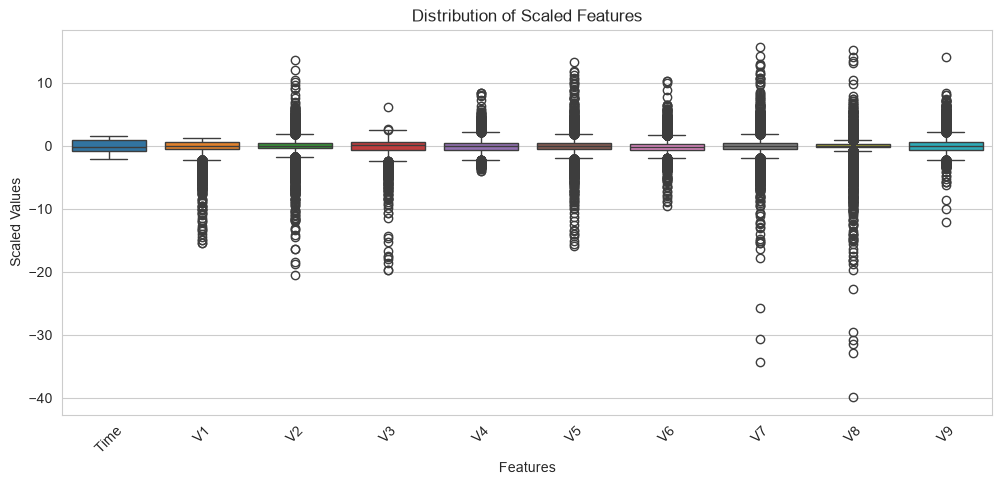

In [22]:
plt.figure(figsize=(12, 5))

sns.boxplot(
    data=X_train_scaled.iloc[:, :10]
)

plt.title("Distribution of Scaled Features")
plt.xlabel("Features")
plt.ylabel("Scaled Values")
plt.xticks(rotation=45)

plt.show()

In [23]:
print("Class in training features:", 'Class' in X_train.columns)
print("Class in testing features:", 'Class' in X_test.columns)

print("Training and testing overlap:",
      len(set(X_train.index) & set(X_test.index)))

print("Training transactions:", len(X_train))
print("Testing transactions:", len(X_test))

Class in training features: False
Class in testing features: False
Training and testing overlap: 0
Training transactions: 35000
Testing transactions: 15000


## ISOLATION FOREST

In [24]:
isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

print("Isolation Forest initialized successfully!")

Isolation Forest initialized successfully!


In [25]:
isolation_forest.fit(X_train_scaled)

print("Isolation Forest training completed!")

Isolation Forest training completed!


In [26]:
if_scores = -isolation_forest.score_samples(X_test_scaled)

print("Anomaly scores generated!")
print("Minimum score:", if_scores.min())
print("Maximum score:", if_scores.max())

Anomaly scores generated!
Minimum score: 0.35751647784397333
Maximum score: 0.7365342262431968


In [27]:
if_predictions = isolation_forest.predict(X_test_scaled)

if_flags = (if_predictions == -1).astype(int)

print("Normal transactions:", (if_flags == 0).sum())
print("Anomalous transactions:", (if_flags == 1).sum())

Normal transactions: 14853
Anomalous transactions: 147


In [28]:
if_results = X_test.copy()

if_results['Actual_Class'] = y_test
if_results['Anomaly_Score'] = if_scores
if_results['IF_Flag'] = if_flags

display(if_results.head())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V24,V25,V26,V27,V28,Amount_log,Amount,Actual_Class,Anomaly_Score,IF_Flag
152784,97464.0,1.950375,-0.732294,-1.204485,-0.568751,1.506499,4.067329,-1.619239,1.056602,2.505489,...,0.669422,-0.585260,0.462775,-0.020554,-0.049449,2.830268,2.830268,0,0.442957,0
66285,51974.0,-0.096787,-0.023614,1.617135,-0.799403,-0.832230,0.171896,-0.568508,0.115599,-0.899669,...,-0.226988,-0.835844,-0.012135,0.127304,0.192158,3.135494,3.135494,0,0.406481,0
167724,118853.0,2.028856,-0.353547,-0.619767,0.239796,-0.327517,-0.106119,-0.625842,0.052316,1.322995,...,0.416420,-0.105118,-0.253715,0.030704,-0.034752,0.779325,0.779325,0,0.377225,0
192332,129639.0,0.043404,0.019064,0.732060,-1.788293,-0.107506,-1.063996,0.222227,-0.229100,-0.988301,...,0.085548,-0.790463,-0.340048,0.216101,0.221798,1.064711,1.064711,0,0.398808,0
91102,63314.0,1.387340,-0.896362,0.291132,-2.174364,-1.292434,-0.919059,-0.685396,-0.228880,0.356665,...,-0.077408,0.450131,0.082543,0.045958,0.027123,3.650658,3.650658,0,0.404847,0


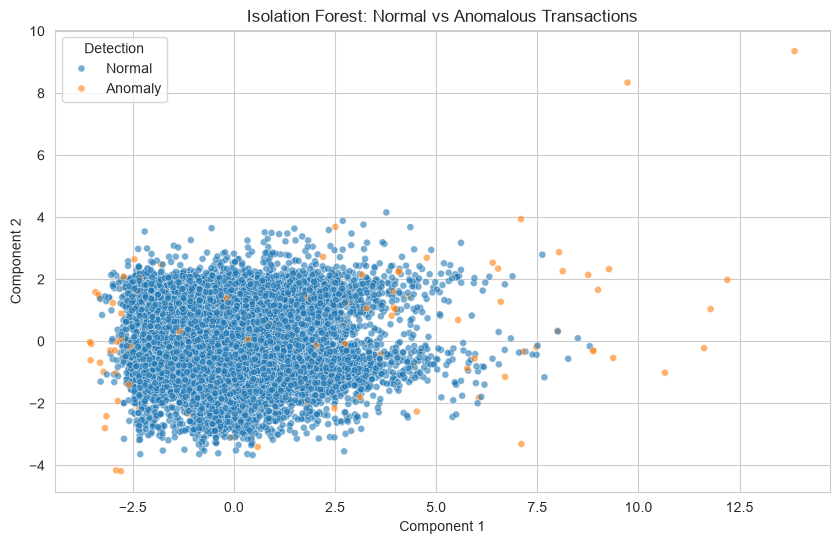

In [29]:
pca_visual = PCA(n_components=2)

X_visual = pca_visual.fit_transform(X_test_scaled)

visual_df = pd.DataFrame({
    'Component 1': X_visual[:, 0],
    'Component 2': X_visual[:, 1],
    'Detection': np.where(if_flags == 1, 'Anomaly', 'Normal')
})

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=visual_df,
    x='Component 1',
    y='Component 2',
    hue='Detection',
    alpha=0.6,
    s=25
)

plt.title("Isolation Forest: Normal vs Anomalous Transactions")
plt.show()

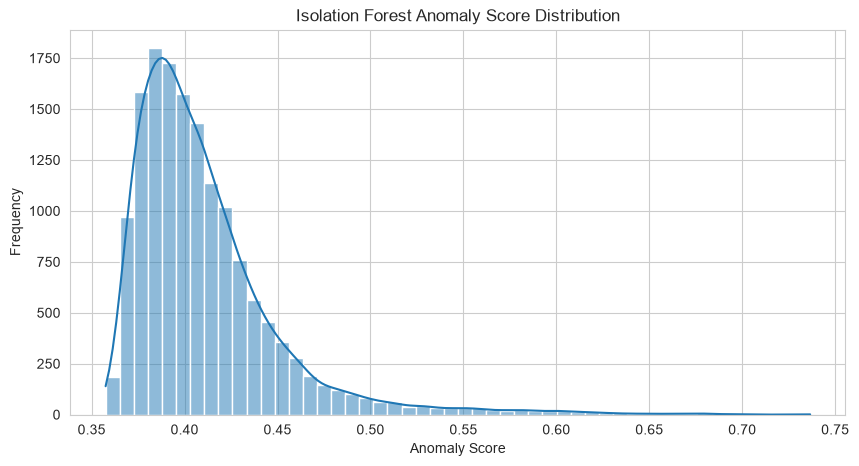

In [30]:
plt.figure(figsize=(10, 5))

sns.histplot(
    if_scores,
    bins=50,
    kde=True
)

plt.title("Isolation Forest Anomaly Score Distribution")
plt.xlabel("Anomaly Score")
plt.ylabel("Frequency")

plt.show()

In [31]:
if_ranked = if_results.sort_values(
    by='Anomaly_Score',
    ascending=False
).copy()

if_ranked.insert(
    0,
    'Anomaly_Rank',
    range(1, len(if_ranked) + 1)
)

display(
    if_ranked[
        ['Anomaly_Rank', 'Amount', 'Anomaly_Score', 'Actual_Class', 'IF_Flag']
    ].head(20)
)

,Anomaly_Rank,Amount,Anomaly_Score,Actual_Class,IF_Flag
43428,1,5.900418,0.736534,1,1
108424,2,7.120275,0.732591,0,1
68454,3,0.693147,0.695233,0,1
68631,4,0.779325,0.694192,0,1
150697,5,4.584967,0.689376,1,1
201869,6,6.494329,0.688219,0,1
9252,7,0.693147,0.680045,1,1
30709,8,0.693147,0.678992,0,1
229036,9,7.099202,0.678165,0,1
236429,10,5.030438,0.677937,0,1


In [32]:
print("Total flagged transactions:", if_flags.sum())

print(
    "Actual fraud among flagged:",
    int(((if_flags == 1) & (y_test.values == 1)).sum())
)

print(
    "False alarms:",
    int(((if_flags == 1) & (y_test.values == 0)).sum())
)

Total flagged transactions: 147
Actual fraud among flagged: 13
False alarms: 134


## LOCAL OUTLIER FACTOR

In [33]:
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.01,
    novelty=True,
    n_jobs=-1
)

print("LOF initialized successfully!")

LOF initialized successfully!


In [34]:
lof.fit(X_train_scaled)

print("LOF training completed!")

LOF training completed!


In [35]:
lof_scores = -lof.score_samples(X_test_scaled)

print("LOF anomaly scores generated!")
print("Minimum score:", lof_scores.min())
print("Maximum score:", lof_scores.max())

LOF anomaly scores generated!
Minimum score: 0.9380831520507886
Maximum score: 3.375178987311055


In [36]:
lof_predictions = lof.predict(X_test_scaled)

lof_flags = (lof_predictions == -1).astype(int)

print("Normal transactions:", (lof_flags == 0).sum())
print("Anomalous transactions:", (lof_flags == 1).sum())

Normal transactions: 14845
Anomalous transactions: 155


In [37]:
lof_results = X_test.copy()

lof_results['Actual_Class'] = y_test
lof_results['Anomaly_Score'] = lof_scores
lof_results['LOF_Flag'] = lof_flags

display(lof_results.head())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V24,V25,V26,V27,V28,Amount_log,Amount,Actual_Class,Anomaly_Score,LOF_Flag
152784,97464.0,1.950375,-0.732294,-1.204485,-0.568751,1.506499,4.067329,-1.619239,1.056602,2.505489,...,0.669422,-0.585260,0.462775,-0.020554,-0.049449,2.830268,2.830268,0,1.063873,0
66285,51974.0,-0.096787,-0.023614,1.617135,-0.799403,-0.832230,0.171896,-0.568508,0.115599,-0.899669,...,-0.226988,-0.835844,-0.012135,0.127304,0.192158,3.135494,3.135494,0,1.138958,0
167724,118853.0,2.028856,-0.353547,-0.619767,0.239796,-0.327517,-0.106119,-0.625842,0.052316,1.322995,...,0.416420,-0.105118,-0.253715,0.030704,-0.034752,0.779325,0.779325,0,1.180767,0
192332,129639.0,0.043404,0.019064,0.732060,-1.788293,-0.107506,-1.063996,0.222227,-0.229100,-0.988301,...,0.085548,-0.790463,-0.340048,0.216101,0.221798,1.064711,1.064711,0,1.029117,0
91102,63314.0,1.387340,-0.896362,0.291132,-2.174364,-1.292434,-0.919059,-0.685396,-0.228880,0.356665,...,-0.077408,0.450131,0.082543,0.045958,0.027123,3.650658,3.650658,0,1.025111,0


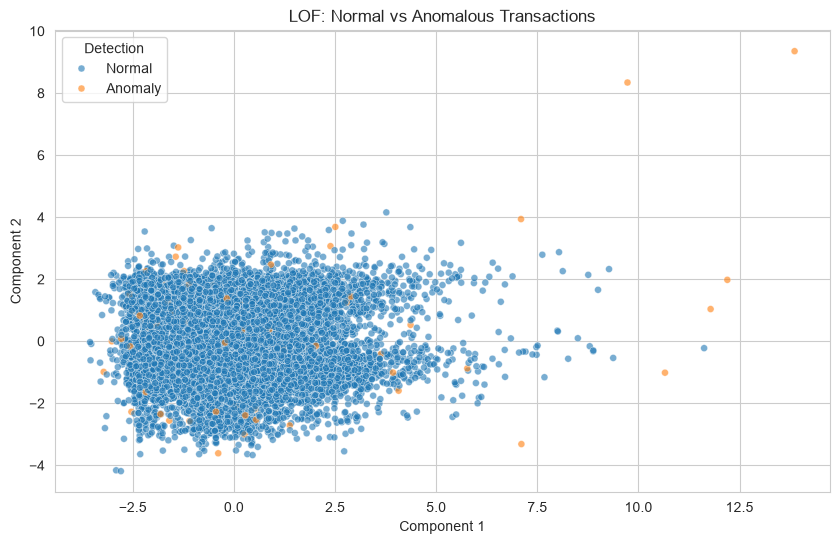

In [38]:
lof_visual_df = pd.DataFrame({
    'Component 1': X_visual[:, 0],
    'Component 2': X_visual[:, 1],
    'Detection': np.where(lof_flags == 1, 'Anomaly', 'Normal')
})

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=lof_visual_df,
    x='Component 1',
    y='Component 2',
    hue='Detection',
    alpha=0.6,
    s=25
)

plt.title("LOF: Normal vs Anomalous Transactions")
plt.show()

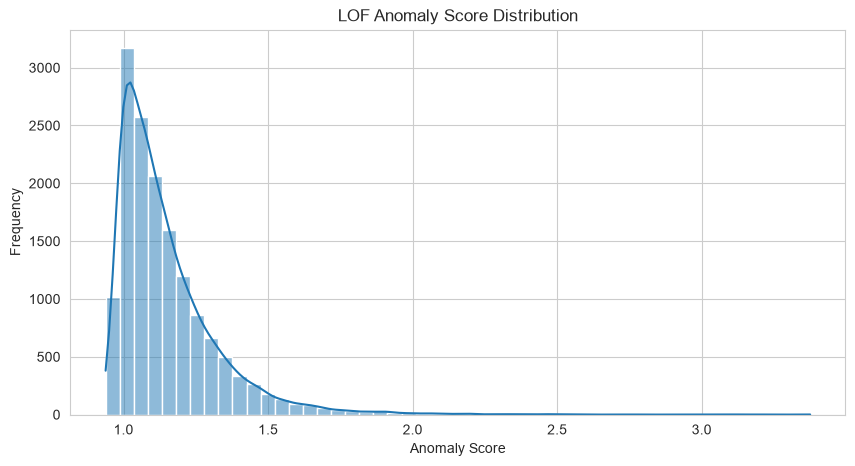

In [39]:
plt.figure(figsize=(10, 5))

sns.histplot(lof_scores, bins=50, kde=True)

plt.title("LOF Anomaly Score Distribution")
plt.xlabel("Anomaly Score")
plt.ylabel("Frequency")

plt.show()

In [40]:
lof_ranked = lof_results.sort_values(
    by='Anomaly_Score',
    ascending=False
).copy()

lof_ranked.insert(0, 'Anomaly_Rank', range(1, len(lof_ranked) + 1))

display(
    lof_ranked[
        ['Anomaly_Rank', 'Amount', 'Anomaly_Score', 'Actual_Class', 'LOF_Flag']
    ].head(20)
)

,Anomaly_Rank,Amount,Anomaly_Score,Actual_Class,LOF_Flag
229036,1,7.099202,3.375179,0,1
4231,2,1.791759,3.190548,0,1
108424,3,7.120275,3.104437,0,1
201869,4,6.494329,3.070314,0,1
262283,5,1.091923,3.063874,0,1
63551,6,3.641788,3.029174,0,1
236429,7,5.030438,2.934288,0,1
279744,8,3.211650,2.913878,0,1
10898,9,2.772589,2.751951,0,1
68227,10,0.636577,2.598963,0,1


In [41]:
print("Total flagged transactions:", lof_flags.sum())

print(
    "Actual fraud among flagged:",
    int(((lof_flags == 1) & (y_test.values == 1)).sum())
)

print(
    "False alarms:",
    int(((lof_flags == 1) & (y_test.values == 0)).sum())
)

Total flagged transactions: 155
Actual fraud among flagged: 3
False alarms: 152


## PCA RECONSTRUCTOR ERROR

In [42]:
pca = PCA(n_components=10)

print("PCA initialized successfully!")

PCA initialized successfully!


In [43]:
pca.fit(X_train_scaled)

print("PCA training completed!")
print("Explained variance ratio:", pca.explained_variance_ratio_.sum())

PCA training completed!
Explained variance ratio: 0.42176479176123993


In [44]:
X_test_pca = pca.transform(X_test_scaled)

print("PCA transformation completed!")
print("Original test shape:", X_test_scaled.shape)
print("Reduced test shape:", X_test_pca.shape)

PCA transformation completed!
Original test shape: (15000, 31)
Reduced test shape: (15000, 10)


In [45]:
X_test_reconstructed = pca.inverse_transform(X_test_pca)

print("Test data reconstruction completed!")
print("Reconstructed shape:", X_test_reconstructed.shape)

Test data reconstruction completed!
Reconstructed shape: (15000, 31)


In [46]:
pca_scores = np.mean(
    (X_test_scaled.values - X_test_reconstructed) ** 2,
    axis=1
)

print("PCA reconstruction errors calculated!")
print("Minimum error:", pca_scores.min())
print("Maximum error:", pca_scores.max())

PCA reconstruction errors calculated!
Minimum error: 0.07693739887098015
Maximum error: 125.4307121300271


In [47]:
X_train_pca = pca.transform(X_train_scaled)

X_train_reconstructed = pca.inverse_transform(X_train_pca)

pca_train_scores = np.mean(
    (X_train_scaled.values - X_train_reconstructed) ** 2,
    axis=1
)

pca_threshold = np.percentile(pca_train_scores, 99)

pca_flags = (pca_scores > pca_threshold).astype(int)

print("PCA anomaly threshold:", pca_threshold)
print("Normal transactions:", (pca_flags == 0).sum())
print("Anomalous transactions:", (pca_flags == 1).sum())

PCA anomaly threshold: 3.9497011289487096
Normal transactions: 14867
Anomalous transactions: 133


In [48]:
pca_results = X_test.copy()

pca_results['Actual_Class'] = y_test
pca_results['Anomaly_Score'] = pca_scores
pca_results['PCA_Flag'] = pca_flags

display(pca_results.head())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V24,V25,V26,V27,V28,Amount_log,Amount,Actual_Class,Anomaly_Score,PCA_Flag
152784,97464.0,1.950375,-0.732294,-1.204485,-0.568751,1.506499,4.067329,-1.619239,1.056602,2.505489,...,0.669422,-0.585260,0.462775,-0.020554,-0.049449,2.830268,2.830268,0,0.536877,0
66285,51974.0,-0.096787,-0.023614,1.617135,-0.799403,-0.832230,0.171896,-0.568508,0.115599,-0.899669,...,-0.226988,-0.835844,-0.012135,0.127304,0.192158,3.135494,3.135494,0,0.512527,0
167724,118853.0,2.028856,-0.353547,-0.619767,0.239796,-0.327517,-0.106119,-0.625842,0.052316,1.322995,...,0.416420,-0.105118,-0.253715,0.030704,-0.034752,0.779325,0.779325,0,0.202510,0
192332,129639.0,0.043404,0.019064,0.732060,-1.788293,-0.107506,-1.063996,0.222227,-0.229100,-0.988301,...,0.085548,-0.790463,-0.340048,0.216101,0.221798,1.064711,1.064711,0,0.435243,0
91102,63314.0,1.387340,-0.896362,0.291132,-2.174364,-1.292434,-0.919059,-0.685396,-0.228880,0.356665,...,-0.077408,0.450131,0.082543,0.045958,0.027123,3.650658,3.650658,0,0.457690,0


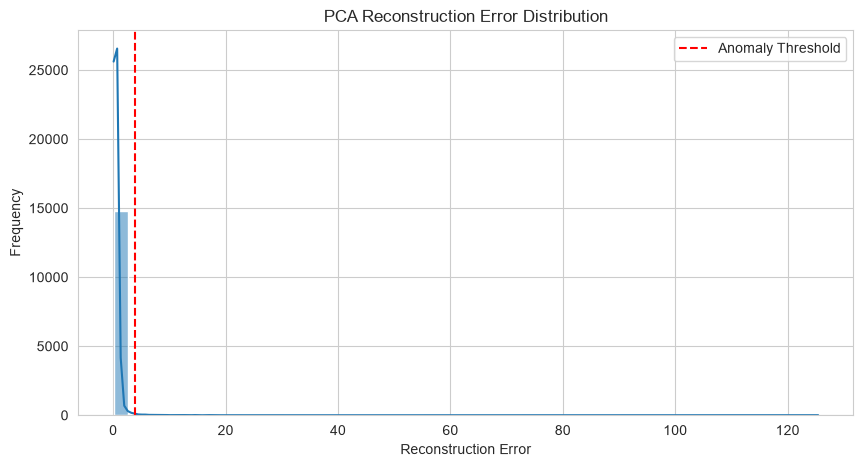

In [49]:
plt.figure(figsize=(10, 5))

sns.histplot(pca_scores, bins=50, kde=True)

plt.axvline(
    pca_threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.title("PCA Reconstruction Error Distribution")
plt.xlabel("Reconstruction Error")
plt.ylabel("Frequency")
plt.legend()
plt.show()

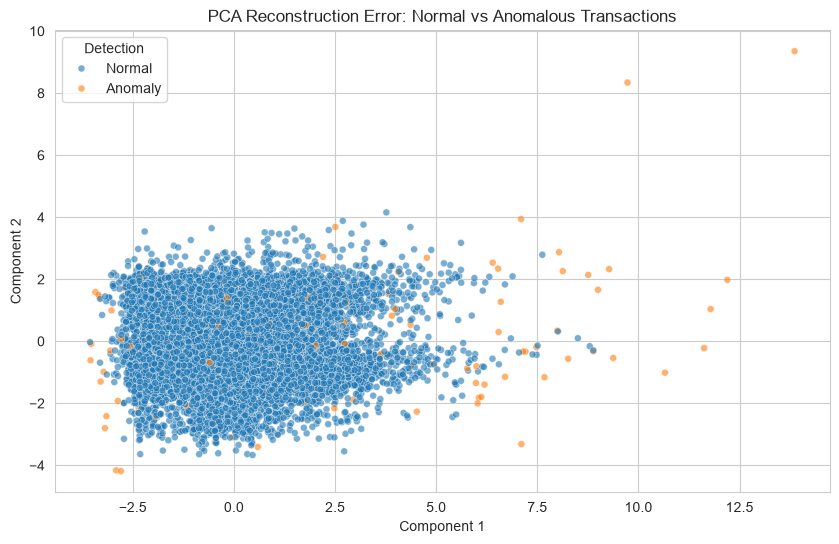

In [50]:
pca_visual_df = pd.DataFrame({
    'Component 1': X_visual[:, 0],
    'Component 2': X_visual[:, 1],
    'Detection': np.where(pca_flags == 1, 'Anomaly', 'Normal')
})

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_visual_df,
    x='Component 1',
    y='Component 2',
    hue='Detection',
    alpha=0.6,
    s=25
)

plt.title("PCA Reconstruction Error: Normal vs Anomalous Transactions")
plt.show()

In [51]:
pca_ranked = pca_results.sort_values(
    by='Anomaly_Score',
    ascending=False
).copy()

pca_ranked.insert(0, 'Anomaly_Rank', range(1, len(pca_ranked) + 1))

display(
    pca_ranked[
        ['Anomaly_Rank', 'Amount', 'Anomaly_Score', 'Actual_Class', 'PCA_Flag']
    ].head(20)
)

,Anomaly_Rank,Amount,Anomaly_Score,Actual_Class,PCA_Flag
108424,1,7.120275,125.430712,0,1
201869,2,6.494329,123.038626,0,1
229036,3,7.099202,80.964351,0,1
236429,4,5.030438,68.603999,0,1
63551,5,3.641788,61.455661,0,1
42635,6,2.516082,55.413437,1,1
8615,7,0.693147,51.099563,1,1
9252,8,0.693147,48.218357,1,1
43428,9,5.900418,44.190940,1,1
18570,10,8.564172,43.185989,0,1


In [52]:
print("Total flagged transactions:", pca_flags.sum())

print(
    "Actual fraud among flagged:",
    int(((pca_flags == 1) & (y_test.values == 1)).sum())
)

print(
    "False alarms:",
    int(((pca_flags == 1) & (y_test.values == 0)).sum())
)

Total flagged transactions: 133
Actual fraud among flagged: 16
False alarms: 117


## ROBUST Z-SCORE


In [53]:
feature_median = X_train_scaled.median()

feature_mad = (
    X_train_scaled - feature_median
).abs().median()

feature_mad = feature_mad.replace(0, np.nan)

print("Median calculated successfully!")
print("MAD calculated successfully!")

Median calculated successfully!
MAD calculated successfully!


In [54]:
robust_z_scores = (
    (X_test_scaled - feature_median).abs()
    / (1.4826 * feature_mad)
)

robust_z_scores = robust_z_scores.fillna(0)

print("Robust Z-scores calculated successfully!")

Robust Z-scores calculated successfully!


In [55]:
robust_scores = robust_z_scores.apply(
    lambda row: row.nlargest(5).mean(),
    axis=1
)

print("Robust anomaly scores generated!")
print("Minimum score:", robust_scores.min())
print("Maximum score:", robust_scores.max())

Robust anomaly scores generated!
Minimum score: 0.8193063575537357
Maximum score: 68.1576887355702


In [56]:
train_robust_z_scores = (
    (X_train_scaled - feature_median).abs()
    / (1.4826 * feature_mad)
)

train_robust_z_scores = train_robust_z_scores.fillna(0)

train_robust_scores = train_robust_z_scores.apply(
    lambda row: row.nlargest(5).mean(),
    axis=1
)

robust_threshold = np.percentile(train_robust_scores, 99)

robust_flags = (robust_scores > robust_threshold).astype(int)

print("Robust Z-score threshold:", robust_threshold)
print("Normal transactions:", (robust_flags == 0).sum())
print("Anomalous transactions:", (robust_flags == 1).sum())

Robust Z-score threshold: 12.154518579315146
Normal transactions: 14859
Anomalous transactions: 141


In [57]:
robust_results = X_test.copy()

robust_results['Actual_Class'] = y_test
robust_results['Anomaly_Score'] = robust_scores
robust_results['Robust_Flag'] = robust_flags

display(robust_results.head())

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V24,V25,V26,V27,V28,Amount_log,Amount,Actual_Class,Anomaly_Score,Robust_Flag
152784,97464.0,1.950375,-0.732294,-1.204485,-0.568751,1.506499,4.067329,-1.619239,1.056602,2.505489,...,0.669422,-0.585260,0.462775,-0.020554,-0.049449,2.830268,2.830268,0,3.127223,0
66285,51974.0,-0.096787,-0.023614,1.617135,-0.799403,-0.832230,0.171896,-0.568508,0.115599,-0.899669,...,-0.226988,-0.835844,-0.012135,0.127304,0.192158,3.135494,3.135494,0,1.837209,0
167724,118853.0,2.028856,-0.353547,-0.619767,0.239796,-0.327517,-0.106119,-0.625842,0.052316,1.322995,...,0.416420,-0.105118,-0.253715,0.030704,-0.034752,0.779325,0.779325,0,1.287774,0
192332,129639.0,0.043404,0.019064,0.732060,-1.788293,-0.107506,-1.063996,0.222227,-0.229100,-0.988301,...,0.085548,-0.790463,-0.340048,0.216101,0.221798,1.064711,1.064711,0,1.810717,0
91102,63314.0,1.387340,-0.896362,0.291132,-2.174364,-1.292434,-0.919059,-0.685396,-0.228880,0.356665,...,-0.077408,0.450131,0.082543,0.045958,0.027123,3.650658,3.650658,0,1.896756,0


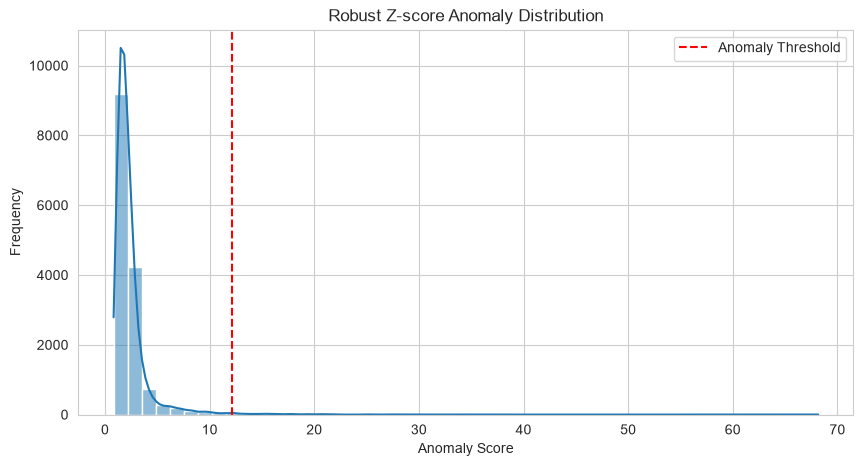

In [58]:
plt.figure(figsize=(10, 5))

sns.histplot(robust_scores, bins=50, kde=True)

plt.axvline(
    robust_threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.title("Robust Z-score Anomaly Distribution")
plt.xlabel("Anomaly Score")
plt.ylabel("Frequency")
plt.legend()
plt.show()

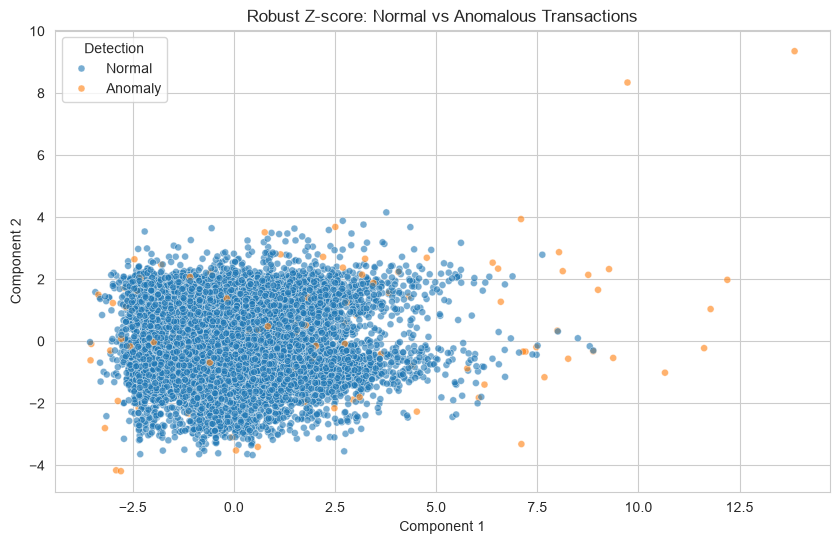

In [59]:
robust_visual_df = pd.DataFrame({
    'Component 1': X_visual[:, 0],
    'Component 2': X_visual[:, 1],
    'Detection': np.where(robust_flags == 1, 'Anomaly', 'Normal')
})

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=robust_visual_df,
    x='Component 1',
    y='Component 2',
    hue='Detection',
    alpha=0.6,
    s=25
)

plt.title("Robust Z-score: Normal vs Anomalous Transactions")
plt.show()

In [60]:
robust_ranked = robust_results.sort_values(
    by='Anomaly_Score',
    ascending=False
).copy()

robust_ranked.insert(
    0,
    'Anomaly_Rank',
    range(1, len(robust_ranked) + 1)
)

display(
    robust_ranked[
        ['Anomaly_Rank', 'Amount', 'Anomaly_Score', 'Actual_Class', 'Robust_Flag']
    ].head(20)
)

,Anomaly_Rank,Amount,Anomaly_Score,Actual_Class,Robust_Flag
108424,1,7.120275,68.157689,0,1
201869,2,6.494329,66.779029,0,1
229036,3,7.099202,44.880800,0,1
41667,4,3.587677,38.026104,0,1
30709,5,0.693147,37.241046,0,1
30626,6,0.693147,36.695776,0,1
211925,7,6.071846,35.535592,0,1
18570,8,8.564172,34.772952,0,1
63551,9,3.641788,33.894802,0,1
68631,10,0.779325,33.866985,0,1


In [61]:
print("Total flagged transactions:", robust_flags.sum())

print(
    "Actual fraud among flagged:",
    int(((robust_flags == 1) & (y_test.values == 1)).sum())
)

print(
    "False alarms:",
    int(((robust_flags == 1) & (y_test.values == 0)).sum())
)

Total flagged transactions: 141
Actual fraud among flagged: 8
False alarms: 133


## Performance Evaluation and Comparison

In [62]:
comparison_data = pd.DataFrame({
    'Actual_Class': y_test,
    'IF_Flag': if_flags,
    'LOF_Flag': lof_flags,
    'PCA_Flag': pca_flags,
    'Robust_Flag': robust_flags,
    'IF_Score': if_scores,
    'LOF_Score': lof_scores,
    'PCA_Score': pca_scores,
    'Robust_Score': robust_scores
}, index=X_test.index)

display(comparison_data.head())

,Actual_Class,IF_Flag,LOF_Flag,PCA_Flag,Robust_Flag,IF_Score,LOF_Score,PCA_Score,Robust_Score
152784,0,0,0,0,0,0.442957,1.063873,0.536877,3.127223
66285,0,0,0,0,0,0.406481,1.138958,0.512527,1.837209
167724,0,0,0,0,0,0.377225,1.180767,0.202510,1.287774
192332,0,0,0,0,0,0.398808,1.029117,0.435243,1.810717
91102,0,0,0,0,0,0.404847,1.025111,0.457690,1.896756


In [63]:
model_predictions = {
    'Isolation Forest': if_flags,
    'LOF': lof_flags,
    'PCA Reconstruction': pca_flags,
    'Robust Z-score': robust_flags
}

model_scores = {
    'Isolation Forest': if_scores,
    'LOF': lof_scores,
    'PCA Reconstruction': pca_scores,
    'Robust Z-score': robust_scores
}

evaluation_results = []

for model_name in model_predictions:

    predictions = model_predictions[model_name]
    scores = model_scores[model_name]

    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)
    ap = average_precision_score(y_test, scores)

    evaluation_results.append({
        'Model': model_name,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'Average Precision': ap
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.sort_values(
        by='Average Precision',
        ascending=False
    ).round(4)
)

,Model,Precision,Recall,F1-Score,Average Precision
0,Isolation Forest,0.0884,0.52,0.1512,0.1782
2,PCA Reconstruction,0.1203,0.64,0.2025,0.1700
3,Robust Z-score,0.0567,0.32,0.0964,0.0520
1,LOF,0.0194,0.12,0.0333,0.0083


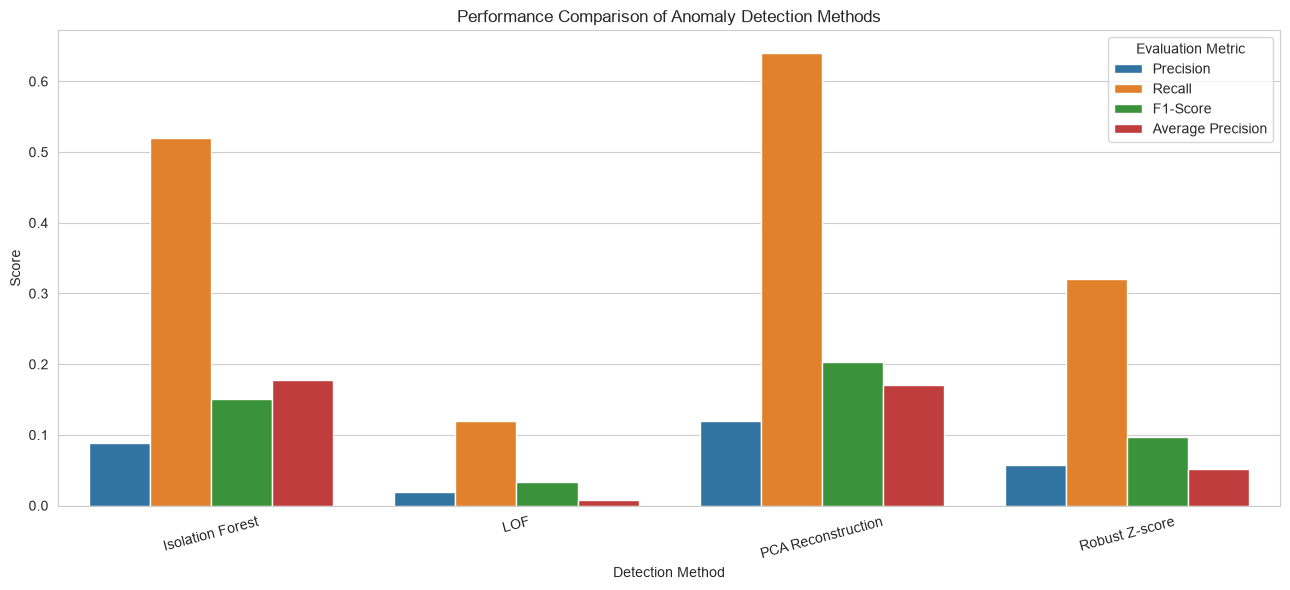

In [64]:
evaluation_plot = evaluation_df.melt(
    id_vars='Model',
    value_vars=['Precision', 'Recall', 'F1-Score', 'Average Precision'],
    var_name='Metric',
    value_name='Score'
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=evaluation_plot,
    x='Model',
    y='Score',
    hue='Metric'
)

plt.title("Performance Comparison of Anomaly Detection Methods")
plt.xlabel("Detection Method")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(title='Evaluation Metric')
plt.tight_layout()
plt.show()

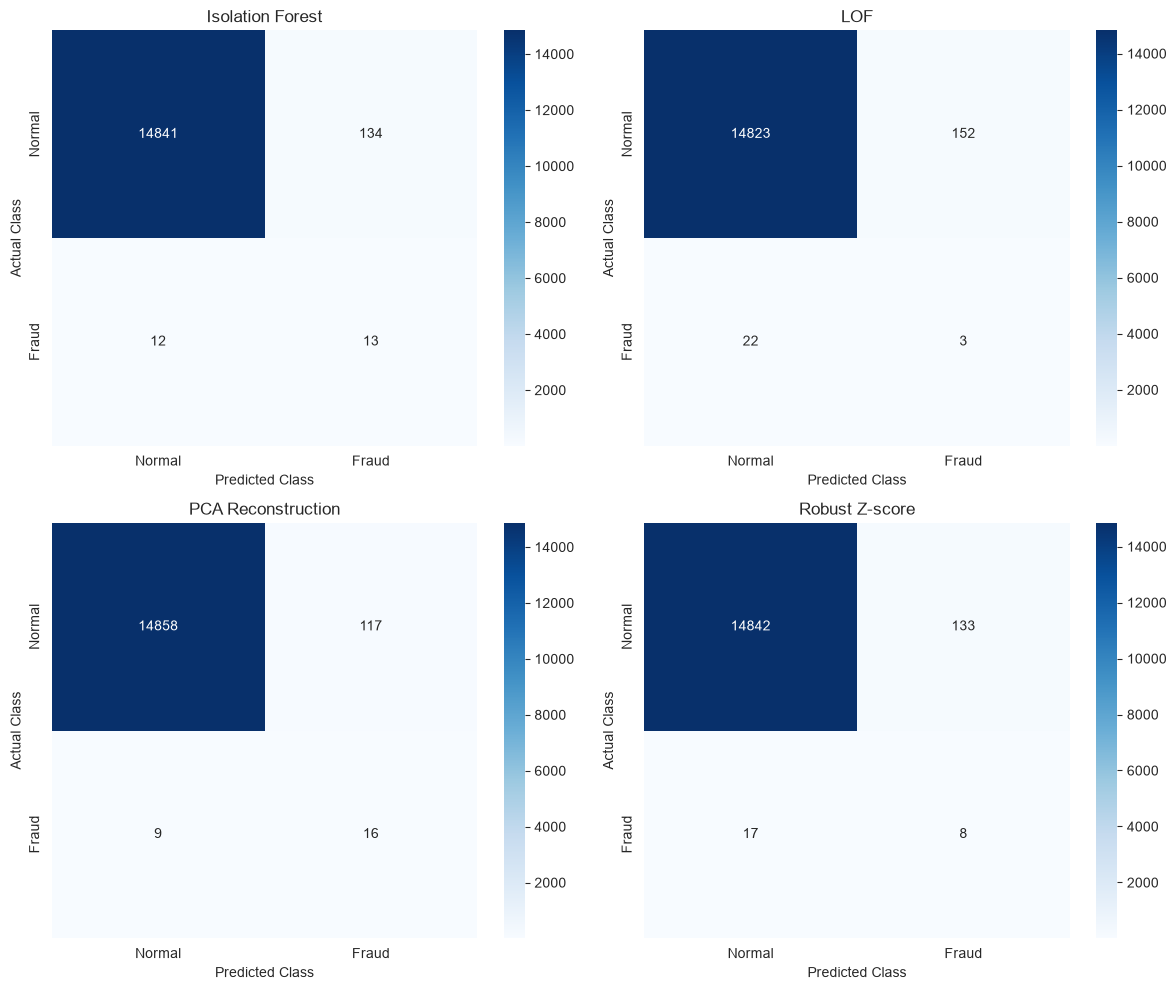

In [65]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (model_name, predictions) in zip(
    axes.flatten(), model_predictions.items()
):

    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax,
        xticklabels=['Normal', 'Fraud'],
        yticklabels=['Normal', 'Fraud']
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

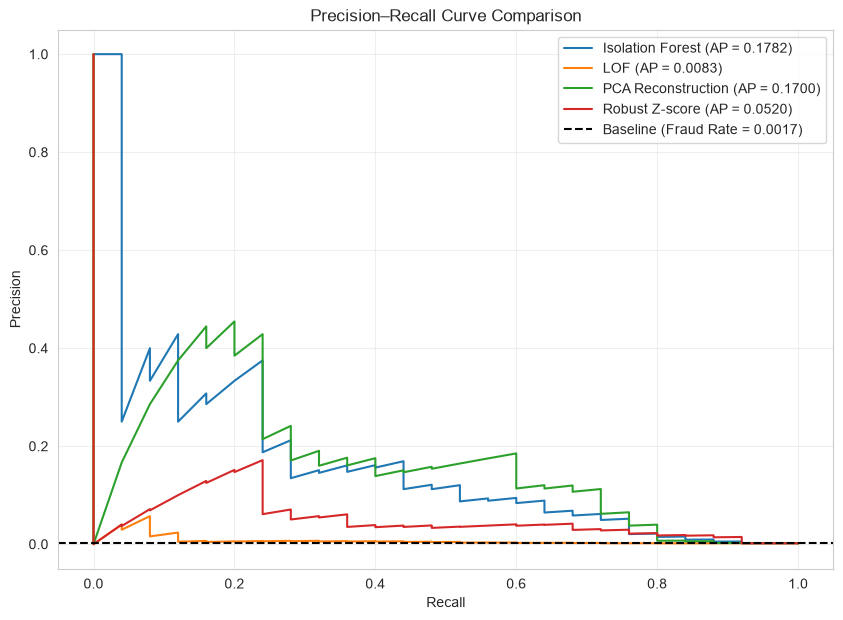

In [66]:
plt.figure(figsize=(10, 7))

for model_name, scores in model_scores.items():

    precision_values, recall_values, thresholds = precision_recall_curve(
        y_test,
        scores
    )

    ap = average_precision_score(y_test, scores)

    plt.plot(
        recall_values,
        precision_values,
        label=f'{model_name} (AP = {ap:.4f})'
    )

fraud_rate = y_test.mean()

plt.axhline(
    fraud_rate,
    linestyle='--',
    color='black',
    label=f'Baseline (Fraud Rate = {fraud_rate:.4f})'
)

plt.title("Precision–Recall Curve Comparison")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [67]:
for model_name, predictions in model_predictions.items():

    print("\n", "=" * 50)
    print(model_name)
    print("=" * 50)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=['Normal', 'Fraud'],
            zero_division=0
        )
    )


Isolation Forest
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00     14975
       Fraud       0.09      0.52      0.15        25

    accuracy                           0.99     15000
   macro avg       0.54      0.76      0.57     15000
weighted avg       1.00      0.99      0.99     15000


LOF
              precision    recall  f1-score   support

      Normal       1.00      0.99      0.99     14975
       Fraud       0.02      0.12      0.03        25

    accuracy                           0.99     15000
   macro avg       0.51      0.55      0.51     15000
weighted avg       1.00      0.99      0.99     15000


PCA Reconstruction
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00     14975
       Fraud       0.12      0.64      0.20        25

    accuracy                           0.99     15000
   macro avg       0.56      0.82      0.60     15000
weighted avg       1.00      0.

## Top-K Suspicious Transaction Ranking and Investigation

In [68]:
original_amounts = data.loc[X_test.index, 'Amount']

comparison_data['Original_Amount'] = original_amounts

print("Original transaction amounts restored!")
display(comparison_data.head())

Original transaction amounts restored!


,Actual_Class,IF_Flag,LOF_Flag,PCA_Flag,Robust_Flag,IF_Score,LOF_Score,PCA_Score,Robust_Score,Original_Amount
152784,0,0,0,0,0,0.442957,1.063873,0.536877,3.127223,15.95
66285,0,0,0,0,0,0.406481,1.138958,0.512527,1.837209,22.00
167724,0,0,0,0,0,0.377225,1.180767,0.202510,1.287774,1.18
192332,0,0,0,0,0,0.398808,1.029117,0.435243,1.810717,1.90
91102,0,0,0,0,0,0.404847,1.025111,0.457690,1.896756,37.50


In [69]:
ranked_transactions = {}

for model_name, score_column in {
    'Isolation Forest': 'IF_Score',
    'LOF': 'LOF_Score',
    'PCA Reconstruction': 'PCA_Score',
    'Robust Z-score': 'Robust_Score'
}.items():

    ranked = comparison_data.sort_values(
        by=score_column,
        ascending=False
    ).copy()

    ranked.insert(0, 'Anomaly_Rank', range(1, len(ranked) + 1))

    ranked_transactions[model_name] = ranked

print("Ranked transaction lists created successfully!")

Ranked transaction lists created successfully!


In [70]:
display(
    ranked_transactions['Isolation Forest'][
        ['Anomaly_Rank', 'Original_Amount', 'IF_Score', 'Actual_Class']
    ].head(20)
)

,Anomaly_Rank,Original_Amount,IF_Score,Actual_Class
43428,1,364.19,0.736534,1
108424,2,1235.79,0.732591,0
68454,3,1.00,0.695233,0
68631,4,1.18,0.694192,0
150697,5,97.00,0.689376,1
201869,6,660.38,0.688219,0
9252,7,1.00,0.680045,1
30709,8,1.00,0.678992,0
229036,9,1210.00,0.678165,0
236429,10,152.00,0.677937,0


In [71]:
display(
    ranked_transactions['LOF'][
        ['Anomaly_Rank', 'Original_Amount', 'LOF_Score', 'Actual_Class']
    ].head(20)
)

,Anomaly_Rank,Original_Amount,LOF_Score,Actual_Class
229036,1,1210.00,3.375179,0
4231,2,5.00,3.190548,0
108424,3,1235.79,3.104437,0
201869,4,660.38,3.070314,0
262283,5,1.98,3.063874,0
63551,6,37.16,3.029174,0
236429,7,152.00,2.934288,0
279744,8,23.82,2.913878,0
10898,9,15.00,2.751951,0
68227,10,0.89,2.598963,0


In [72]:
display(
    ranked_transactions['PCA Reconstruction'][
        ['Anomaly_Rank', 'Original_Amount', 'PCA_Score', 'Actual_Class']
    ].head(20)
)

,Anomaly_Rank,Original_Amount,PCA_Score,Actual_Class
108424,1,1235.79,125.430712,0
201869,2,660.38,123.038626,0
229036,3,1210.00,80.964351,0
236429,4,152.00,68.603999,0
63551,5,37.16,61.455661,0
42635,6,11.38,55.413437,1
8615,7,1.00,51.099563,1
9252,8,1.00,48.218357,1
43428,9,364.19,44.190940,1
18570,10,5239.50,43.185989,0


In [73]:
display(
    ranked_transactions['Robust Z-score'][
        ['Anomaly_Rank', 'Original_Amount', 'Robust_Score', 'Actual_Class']
    ].head(20)
)

,Anomaly_Rank,Original_Amount,Robust_Score,Actual_Class
108424,1,1235.79,68.157689,0
201869,2,660.38,66.779029,0
229036,3,1210.00,44.880800,0
41667,4,35.15,38.026104,0
30709,5,1.00,37.241046,0
30626,6,1.00,36.695776,0
211925,7,432.48,35.535592,0
18570,8,5239.50,34.772952,0
63551,9,37.16,33.894802,0
68631,10,1.18,33.866985,0


In [74]:
k_values = [50, 100, 200, 500]

top_k_results = []

total_fraud = y_test.sum()

for model_name, ranked in ranked_transactions.items():

    for k in k_values:

        top_k = ranked.head(k)

        fraud_found = top_k['Actual_Class'].sum()

        precision_k = fraud_found / k
        recall_k = fraud_found / total_fraud if total_fraud > 0 else 0

        top_k_results.append({
            'Model': model_name,
            'K': k,
            'Fraud Found': int(fraud_found),
            'Precision@K': precision_k,
            'Recall@K': recall_k
        })

top_k_df = pd.DataFrame(top_k_results)

display(top_k_df.round(4))

,Model,K,Fraud Found,Precision@K,Recall@K
0,Isolation Forest,50,7,0.140,0.28
1,Isolation Forest,100,12,0.120,0.48
2,Isolation Forest,200,16,0.080,0.64
3,Isolation Forest,500,19,0.038,0.76
4,LOF,50,2,0.040,0.08
5,LOF,100,2,0.020,0.08
6,LOF,200,3,0.015,0.12
7,LOF,500,3,0.006,0.12
8,PCA Reconstruction,50,8,0.160,0.32
9,PCA Reconstruction,100,15,0.150,0.60


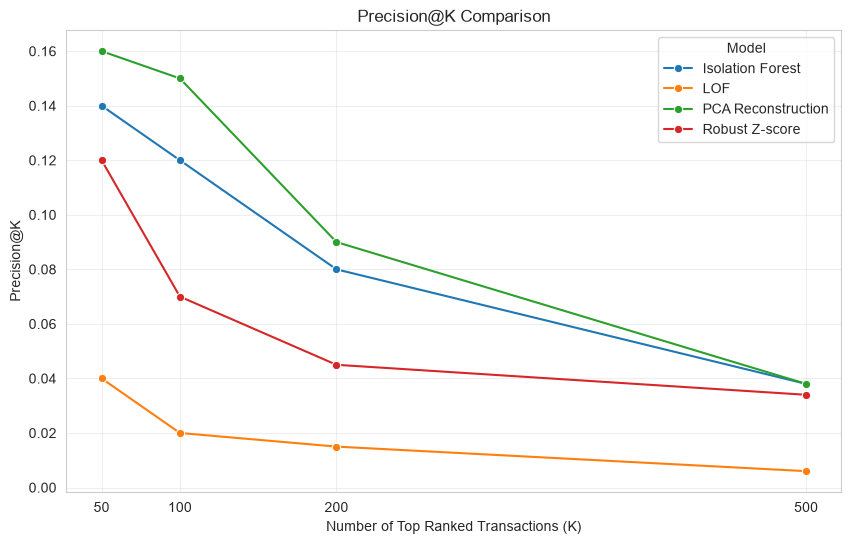

In [75]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=top_k_df,
    x='K',
    y='Precision@K',
    hue='Model',
    marker='o'
)

plt.title("Precision@K Comparison")
plt.xlabel("Number of Top Ranked Transactions (K)")
plt.ylabel("Precision@K")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.show()

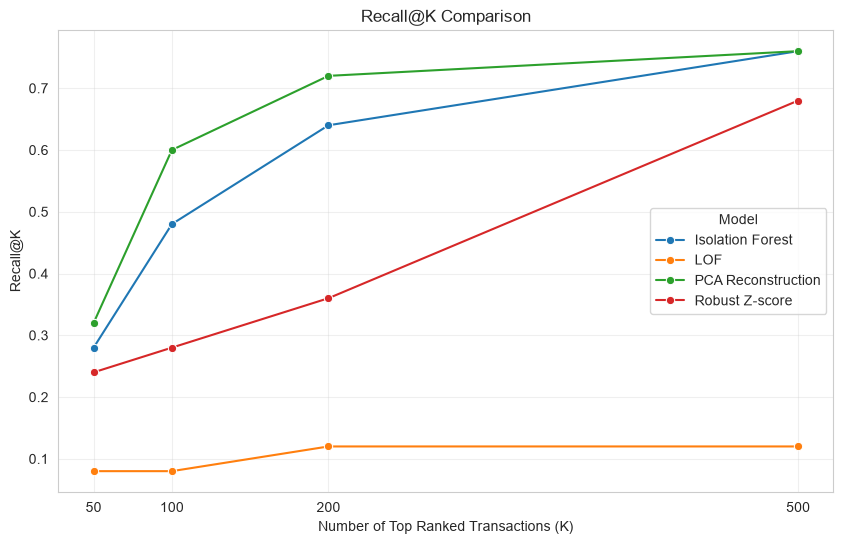

In [76]:
plt.figure(figsize=(10, 6))

sns.lineplot(
    data=top_k_df,
    x='K',
    y='Recall@K',
    hue='Model',
    marker='o'
)

plt.title("Recall@K Comparison")
plt.xlabel("Number of Top Ranked Transactions (K)")
plt.ylabel("Recall@K")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.show()

In [77]:
top_100_if = ranked_transactions['Isolation Forest'].head(100)

fraud_in_top_100 = top_100_if[
    top_100_if['Actual_Class'] == 1
]

false_alarms_in_top_100 = top_100_if[
    top_100_if['Actual_Class'] == 0
]

print("Transactions investigated:", len(top_100_if))
print("Actual fraud cases:", len(fraud_in_top_100))
print("False alarms:", len(false_alarms_in_top_100))

display(
    fraud_in_top_100[
        ['Anomaly_Rank', 'Original_Amount', 'IF_Score']
    ]
)

Transactions investigated: 100
Actual fraud cases: 12
False alarms: 88


,Anomaly_Rank,Original_Amount,IF_Score
43428,1,364.19,0.736534
150697,5,97.00,0.689376
9252,7,1.00,0.680045
8615,13,1.00,0.676516
42635,15,11.38,0.672824
44270,16,1.00,0.671836
154718,33,0.00,0.637560
189701,53,93.35,0.618627
213116,56,8.30,0.616320
215984,62,592.90,0.612036


In [78]:
flag_columns = [
    'IF_Flag',
    'LOF_Flag',
    'PCA_Flag',
    'Robust_Flag'
]

comparison_data['Methods_Flagged'] = comparison_data[
    flag_columns
].sum(axis=1)

print("Transactions flagged by multiple methods:")

display(
    comparison_data[
        comparison_data['Methods_Flagged'] >= 2
    ].sort_values(
        by='Methods_Flagged',
        ascending=False
    )[
        ['Original_Amount', 'Actual_Class', 'Methods_Flagged'] + flag_columns
    ].head(20)
)

Transactions flagged by multiple methods:


,Original_Amount,Actual_Class,Methods_Flagged,IF_Flag,LOF_Flag,PCA_Flag,Robust_Flag
154986,3774.70,0,4,1,1,1,1
173791,3419.12,0,4,1,1,1,1
50735,3200.00,0,4,1,1,1,1
211925,432.48,0,4,1,1,1,1
24160,4.49,0,4,1,1,1,1
227482,0.00,0,4,1,1,1,1
108424,1235.79,0,4,1,1,1,1
18570,5239.50,0,4,1,1,1,1
30709,1.00,0,4,1,1,1,1
68631,1.18,0,4,1,1,1,1


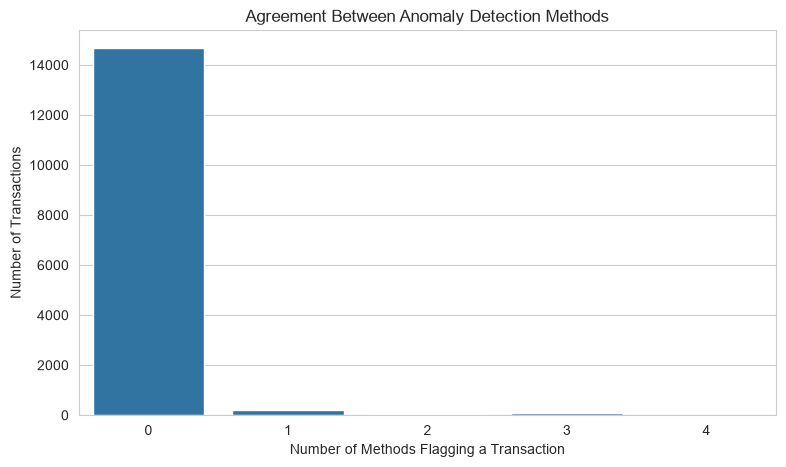

In [79]:
agreement_counts = comparison_data['Methods_Flagged'].value_counts().sort_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=agreement_counts.index,
    y=agreement_counts.values
)

plt.title("Agreement Between Anomaly Detection Methods")
plt.xlabel("Number of Methods Flagging a Transaction")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1, 2, 3, 4])
plt.show()

## Feature-Level Investigation and Final Results

In [80]:
top_100_transactions = ranked_transactions['Isolation Forest'].head(100)

top_100_indices = top_100_transactions.index

top_100_features = X_test_scaled.loc[top_100_indices]

print("Top 100 suspicious transactions selected!")
print("Shape:", top_100_features.shape)

Top 100 suspicious transactions selected!
Shape: (100, 31)


In [81]:
other_transactions = X_test_scaled.drop(index=top_100_indices)

top_100_deviation = top_100_features.abs().mean()
other_deviation = other_transactions.abs().mean()

feature_comparison = pd.DataFrame({
    'Top 100 Suspicious': top_100_deviation,
    'Other Transactions': other_deviation
})

feature_comparison['Difference'] = (
    feature_comparison['Top 100 Suspicious']
    - feature_comparison['Other Transactions']
)

feature_comparison = feature_comparison.sort_values(
    by='Difference',
    ascending=False
)

display(feature_comparison.head(15))

,Top 100 Suspicious,Other Transactions,Difference
V20,6.071346,0.414429,5.656917
V2,6.131179,0.584248,5.546931
V28,5.754345,0.367983,5.386361
V1,5.403360,0.692333,4.711027
V7,5.113024,0.578233,4.534791
V23,4.716838,0.415672,4.301166
V27,4.486757,0.400096,4.086661
V5,4.525043,0.649662,3.875382
V10,4.096022,0.597733,3.498289
V21,3.835759,0.393236,3.442523


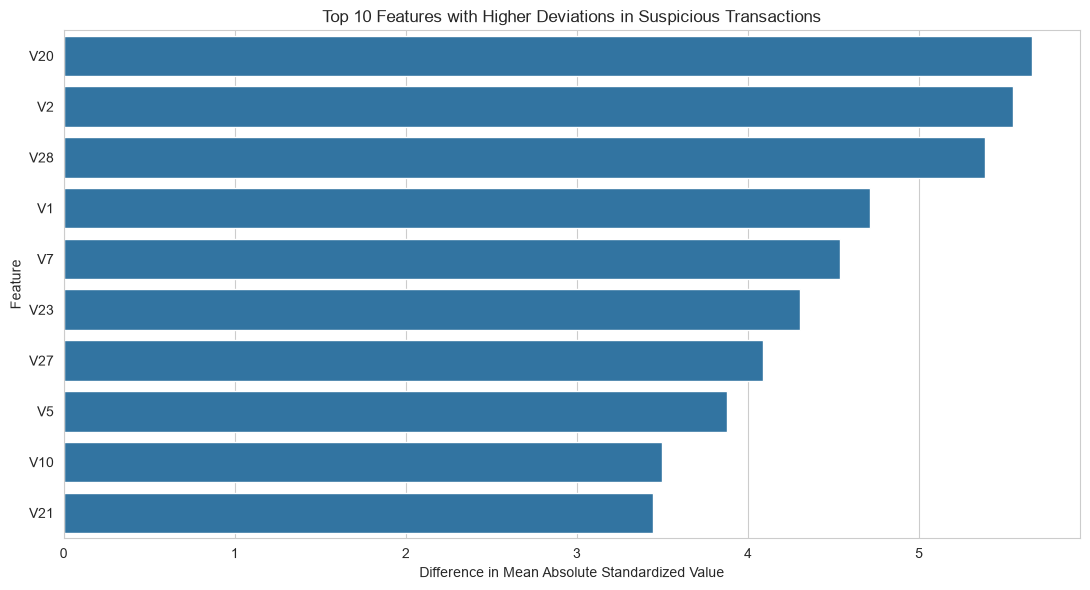

In [82]:
top_features = feature_comparison.head(10).reset_index()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_features,
    x='Difference',
    y='index'
)

plt.title("Top 10 Features with Higher Deviations in Suspicious Transactions")
plt.xlabel("Difference in Mean Absolute Standardized Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [83]:
top_100_investigation = top_100_transactions.copy()

top_100_investigation['Transaction_Type'] = np.where(
    top_100_investigation['Actual_Class'] == 1,
    'Actual Fraud',
    'Normal Transaction'
)

print("Transaction distribution in the top 100:")

display(
    top_100_investigation['Transaction_Type'].value_counts()
)

Transaction distribution in the top 100:


Transaction_Type
Normal Transaction    88
Actual Fraud          12
Name: count, dtype: int64

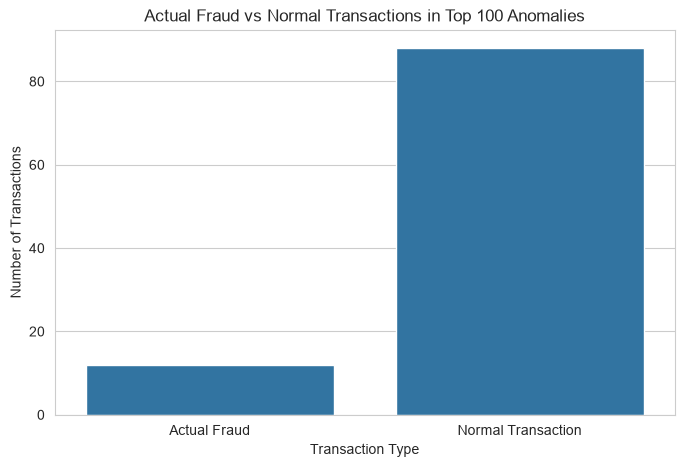

In [84]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=top_100_investigation,
    x='Transaction_Type'
)

plt.title("Actual Fraud vs Normal Transactions in Top 100 Anomalies")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.show()

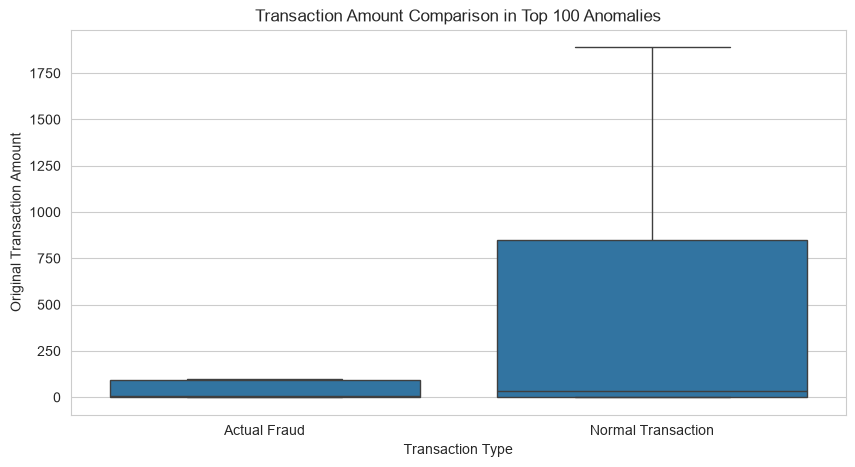

In [85]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=top_100_investigation,
    x='Transaction_Type',
    y='Original_Amount',
    showfliers=False
)

plt.title("Transaction Amount Comparison in Top 100 Anomalies")
plt.xlabel("Transaction Type")
plt.ylabel("Original Transaction Amount")
plt.show()

In [86]:
final_comparison = evaluation_df.copy()

final_comparison = final_comparison.sort_values(
    by='Average Precision',
    ascending=False
).reset_index(drop=True)

final_comparison.insert(
    0,
    'Rank',
    range(1, len(final_comparison) + 1)
)

display(final_comparison.round(4))

,Rank,Model,Precision,Recall,F1-Score,Average Precision
0,1,Isolation Forest,0.0884,0.52,0.1512,0.1782
1,2,PCA Reconstruction,0.1203,0.64,0.2025,0.1700
2,3,Robust Z-score,0.0567,0.32,0.0964,0.0520
3,4,LOF,0.0194,0.12,0.0333,0.0083


In [87]:
best_model = final_comparison.iloc[0]

print("Best model based on Average Precision:")
print("Model:", best_model['Model'])
print("Average Precision:", round(best_model['Average Precision'], 4))
print("Precision:", round(best_model['Precision'], 4))
print("Recall:", round(best_model['Recall'], 4))
print("F1-score:", round(best_model['F1-Score'], 4))

Best model based on Average Precision:
Model: Isolation Forest
Average Precision: 0.1782
Precision: 0.0884
Recall: 0.52
F1-score: 0.1512


In [88]:
for model_name, ranked in ranked_transactions.items():

    filename = model_name.lower().replace(' ', '_') + '_top100.csv'

    ranked.head(100).to_csv(filename, index=True)

    print(filename, "saved successfully!")

isolation_forest_top100.csv saved successfully!
lof_top100.csv saved successfully!
pca_reconstruction_top100.csv saved successfully!
robust_z-score_top100.csv saved successfully!


In [89]:
final_comparison.to_csv(
    'model_performance_comparison.csv',
    index=False
)

top_k_df.to_csv(
    'precision_recall_at_k_comparison.csv',
    index=False
)

feature_comparison.to_csv(
    'feature_deviation_comparison.csv'
)

print("Final project tables exported successfully!")

Final project tables exported successfully!
